# 29 — Warm-start (initial-state) protocol study, System I (fixed controller law)

## Selection criterion — fixed before any result was computed

The initial state of each simulated window is part of the generative model: it encodes
an assumption about how the fault evolves relative to the 60-min window. Choosing the
protocol that looks best on data generated with that same protocol is circular.

**"Optimal" = matches the situation the monitor faces, and degrades gracefully under
mismatch.** The realistic deployment case is an *incipient* fault (test column **P2**:
θ drifts at the 30-day degradation rates, noise on throughout). Rule (implemented in
`scripts/nb29_ws_study.py::stage_select`):

1. **Eligible** = on the P2 column, seed-median marginal SBC KS p ≥ 0.01 for α and β
   **and** seed-median TARP KS p ≥ 0.01 (joint calibration, sensitive to a wrong α–β correlation).
2. Among eligible: lowest seed-mean normalised posterior-mean RMSE on P2; protocols within
   one combined standard error are tied.
3. Tie-break 1: smallest worst-case TARP deviation over the other incipient-fault columns
   (P1, P1b, P3). The abrupt-fault column P0 is a different regime and is reported only.
4. Tie-break 2: simplicity / cost, P1 < P1b < P3 < P2 < P0.
5. If nothing is eligible: lowest P2 TARP deviation, **flagged**; nb31 does not start.

| Protocol | Initial state | Assumption |
|---|---|---|
| P0 | healthy steady state for every θ | abrupt fault at window start |
| P1 | deterministic steady state at θ | incipient fault, noise-free start |
| P1b | P1 + 150-min noisy burn-in | incipient fault, stationary start |
| P2 | θ ramps over a 300-min noisy history at 30-day rates | incipient fault, realistic |
| P3 | steady state at θ′ = θ + N(0, 0.03²) | initial state uncertain (nuisance) |

**Running this notebook.** Execute top to bottom from `notebooks/system_I`. Every stage
skips work already saved in `results/29fx/` and `results/29fx_*.csv`, so after an
interruption simply re-run. Progress sentinels: `results/29fx_progress_*.txt`.


In [1]:
import json, os, sys, time, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N0"   # N0 run; default model is N3 since 2026-11-09
import importlib, system_I_config, ws_protocols, ws_eval, nb29_ws_study
for _m in (system_I_config, ws_protocols, ws_eval, nb29_ws_study):
    importlib.reload(_m)
S = nb29_ws_study
assert S.SENSOR == "N0", S.SENSOR
R, FIGS = ROOT / "results", ROOT / "figures"
P = S.PROTOCOLS

# ---- run switches -----------------------------------------------------------------
PARALLEL_TRAINING = False   # True: train protocol groups in parallel subprocesses (cwd = this folder)
RUN_E4 = False              # optional window-length check (~1-2 h)
THREADS = 4
T0 = time.time()

def load(name):
    f = R / name
    return pd.read_csv(f) if f.exists() else None

## E1 — time scales (deterministic)
Closed-loop eigen time constants, burn-in to stationarity from the exact Lyapunov
solution (no noisy ensemble estimate), settling after an abrupt fault (noise-free,
tolerances far above float32 precision), and the P2 plant lag at realistic and 10× rates.
Replaces the superseded old-law `29_e1_*` files.

**Check:** slowest τ 10–26 min at unsaturated points; `t95_stationary_min` below the
150-min P1b burn-in; finite settling; `lag_Qc_x1` ≲ 3 L/min.

In [2]:
if not (R / "29fx_e1_timescales.csv").exists():
    S.stage_e1()
e1 = load("29fx_e1_timescales.csv"); display(e1.round(4))
assert e1.loc[~e1.saturated_ss, "t95_stationary_min"].max() < 150, \
    "P1b burn-in (150 min) shorter than the time to stationarity: raise burn_min in ws_protocols before E3"


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'point': 'Sc1', 'alpha': 1.0, 'beta': 1.0, 'saturated_ss': False, 'Qc_ss': 43.06547546386719, 'T_ss': 312.5, 'slowest_tau_min': 9.975037108487706, 'fastest_tau_min': 0.23658309507123154, 'min_zeta': 1.0, 't95_stationary_min': np.float64(21.0), 't_settle_abrupt_min': 0.0, 'sd_T_stat': 0.13812011209894134, 'sd_Qc_stat': 24.161551502300114, 'lag_Qc_x1': -0.5443992614746094, 'lag_T_x1': 0.0, 'lag_C_rel_x1': -1.2578486803249689e-06, 'lag_Qc_x10': -0.824798583984375, 'lag_T_x10': 0.0013427734375, 'lag_C_rel_x10': -0.0001296632399316877}
{'point': 'Sc2', 'alpha': 1.0, 'beta': 0.7, 'saturated_ss': True, 'Qc_ss': 400.0, 'T_ss': 312.86895751953125, 'slowest_tau_min': 10.236116863029851, 'fastest_tau_min': 0.09785579398984755, 'min_zeta': 1.0, 't95_stationary_min': np.float64(16.0), 't_settle_abrupt_min': 53.5, 'sd_T_stat': 0.23460174878398687, 'sd_Qc_stat': 0.0, 'lag_Qc_x1': 0.0, 'lag_T_x1': -0.01519775390625, 'lag_C_rel_x1': 0.0013823355548083782, 'lag_Qc_x10': 0.0, 'lag_T_x10': -0.01593017578

,point,alpha,beta,saturated_ss,Qc_ss,T_ss,slowest_tau_min,fastest_tau_min,min_zeta,t95_stationary_min,t_settle_abrupt_min,sd_T_stat,sd_Qc_stat,lag_Qc_x1,lag_T_x1,lag_C_rel_x1,lag_Qc_x10,lag_T_x10,lag_C_rel_x10
0,Sc1,1.00,1.00,False,43.0655,312.5000,9.9750,0.2366,1.0000,21.0,0.0,0.1381,24.1616,-0.5444,0.0000,-0.0000,-0.8248,0.0013,-0.0001
1,Sc2,1.00,0.70,True,400.0000,312.8690,10.2361,0.0979,1.0000,16.0,53.5,0.2346,0.0000,0.0000,-0.0152,0.0014,0.0000,-0.0159,0.0015
2,Sc3,0.70,1.00,False,36.3422,312.5000,9.9568,0.3393,0.9783,19.0,6.0,0.1314,22.1332,-0.3727,0.0000,-0.0000,-0.6907,0.0007,-0.0001
3,Sc4,0.85,0.85,False,92.2729,312.5000,18.8983,0.2789,1.0000,46.0,inf,0.1927,49.3082,-3.3694,0.0000,-0.0000,-5.9322,0.0067,-0.0006
4,Sc5,1.00,0.40,True,400.0000,314.1836,11.0909,0.0988,1.0000,17.0,38.0,0.2433,0.0000,0.0000,-0.0172,0.0016,0.0000,-0.0172,0.0016
5,Sc7,1.00,0.85,False,109.8563,312.5000,26.4083,0.2366,1.0000,56.0,inf,0.2000,57.3231,-4.7911,0.0000,-0.0000,-8.9187,0.0088,-0.0008
6,"c(0.4,0.4)",0.40,0.40,True,400.0000,313.7622,11.0319,0.0988,1.0000,17.0,37.0,0.2527,0.0000,0.0000,-0.0168,0.0015,0.0000,-0.0175,0.0016
7,"c(0.4,1.2)",0.40,1.20,False,18.8811,312.5000,9.9636,0.5876,0.4499,14.0,15.0,0.1092,16.8516,0.0286,0.0000,-0.0000,0.1307,-0.0002,-0.0000
8,"c(1.2,0.4)",1.20,0.40,True,400.0000,314.2297,11.0970,0.0988,1.0000,17.0,38.0,0.2423,0.0000,0.0000,-0.0172,0.0016,0.0000,-0.0167,0.0015
9,"c(1.2,1.2)",1.20,1.20,False,28.6061,312.5000,9.9842,0.1967,0.6991,17.0,9.5,0.1122,17.8631,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


**Reading E1 (2026-11-08 run).** The eigen time constants (10–26 min) and the exact
Lyapunov burn-in (`t95_stationary_min` 14–56 min, all below the 150-min P1b burn-in) are
the reliable E1 numbers. The two noise-free columns are **not**: `t_settle_abrupt_min = inf`
at Sc4/Sc7 and the `lag_Qc_*` offsets (−3 to −5 L/min, not proportional to the rate
multiplier) come from float32 stalling of the integrator in a run with *no* noise (state
increments below one ulp of T ≈ 312 K). The stochastic simulator is unaffected (each
noise increment, ~0.01 K, is far above the ulp). Do not cite those two columns; if needed,
recompute them in a float64 subprocess.

## E2 — where the information is (Fisher information per protocol and representation)
Gaussian FIM with common random numbers. `corr_implied` is the correlation of the inverse
FIM (the local posterior correlation). Representations: 29-D summaries with full vs diagonal
covariance, the raw 120×4 trajectory (Ledoit–Wolf covariance), and the four channel means
only (the "level" information).

In [3]:
if not (R / "29fx_e2_fim.csv").exists():
    S.stage_e2()
e2 = load("29fx_e2_fim.csv")
display(e2.pivot_table(index=["point", "representation"], columns="protocol", values="corr_implied").round(3))
display(e2.pivot_table(index=["point", "representation"], columns="protocol", values="crb_sd_b").round(4))

P0 Sc1 done
P0 Sc2 done
P0 Sc3 done
P0 Sc4 done
P1 Sc1 done
P1 Sc2 done
P1 Sc3 done
P1 Sc4 done
P1b Sc1 done
P1b Sc2 done
P1b Sc3 done
P1b Sc4 done
P2 Sc1 done
P2 Sc2 done
P2 Sc3 done
P2 Sc4 done
P3 Sc1 done
P3 Sc2 done
P3 Sc3 done
P3 Sc4 done
protocol                    P0     P1    P1b     P2     P3
point representation                                      
Sc1   channel_means      0.085 -0.310 -0.216 -0.238 -0.308
      raw_traj_lwcov    -0.021 -0.406 -0.078 -0.120 -0.300
      summaries_diagcov  0.329  0.098  0.035  0.037  0.079
      summaries_fullcov  0.059 -0.408 -0.040 -0.077 -0.307
Sc2   channel_means      0.572  0.787  0.662  0.581  0.764
      raw_traj_lwcov     0.139  0.891  0.643  0.600  0.782
      summaries_diagcov  0.612  0.838  0.772  0.754  0.833
      summaries_fullcov  0.081  0.855  0.482  0.381  0.771
Sc3   channel_means      0.023 -0.292 -0.222 -0.231 -0.293
      raw_traj_lwcov    -0.065 -0.384 -0.111 -0.143 -0.324
      summaries_diagcov  0.309  0.114  0.059  0.

protocol                    P0     P1    P1b     P2     P3
point representation                                      
Sc1   channel_means      0.085 -0.310 -0.216 -0.238 -0.308
      raw_traj_lwcov    -0.021 -0.406 -0.078 -0.120 -0.300
      summaries_diagcov  0.329  0.098  0.035  0.037  0.079
      summaries_fullcov  0.059 -0.408 -0.040 -0.077 -0.307
Sc2   channel_means      0.572  0.787  0.662  0.581  0.764
      raw_traj_lwcov     0.139  0.891  0.643  0.600  0.782
      summaries_diagcov  0.612  0.838  0.772  0.754  0.833
      summaries_fullcov  0.081  0.855  0.482  0.381  0.771
Sc3   channel_means      0.023 -0.292 -0.222 -0.231 -0.293
      raw_traj_lwcov    -0.065 -0.384 -0.111 -0.143 -0.324
      summaries_diagcov  0.309  0.114  0.059  0.058  0.102
      summaries_fullcov  0.049 -0.332 -0.061 -0.071 -0.280
Sc4   channel_means      0.332 -0.694 -0.170 -0.242 -0.216
      raw_traj_lwcov     0.025 -0.504  0.010 -0.015 -0.002
      summaries_diagcov  0.480  0.054  0.043  0.039 -0.020
      summaries_fullcov  0.087 -0.689  0.042 -0.007  0.022

protocol                     P0      P1     P1b      P2      P3
point representation                                           
Sc1   channel_means      0.0440  0.0413  0.0429  0.0431  0.0411
      raw_traj_lwcov     0.0357  0.0257  0.0330  0.0328  0.0270
      summaries_diagcov  0.0215  0.0209  0.0207  0.0208  0.0208
      summaries_fullcov  0.0387  0.0312  0.0361  0.0361  0.0317
Sc2   channel_means      0.0439  0.0462  0.0421  0.0385  0.0457
      raw_traj_lwcov     0.0292  0.0295  0.0324  0.0301  0.0328
      summaries_diagcov  0.0159  0.0244  0.0200  0.0187  0.0241
      summaries_fullcov  0.0353  0.0390  0.0351  0.0329  0.0400
Sc3   channel_means      0.0454  0.0429  0.0445  0.0446  0.0428
      raw_traj_lwcov     0.0368  0.0292  0.0348  0.0346  0.0298
      summaries_diagcov  0.0235  0.0228  0.0226  0.0227  0.0227
      summaries_fullcov  0.0387  0.0332  0.0370  0.0371  0.0335
Sc4   channel_means      0.0422  0.0282  0.0314  0.0312  0.0276
      raw_traj_lwcov     0.0321  0.0056  0.0239  0.0226  0.0205
      summaries_diagcov  0.0168  0.0119  0.0124  0.0124  0.0112
      summaries_fullcov  0.0369  0.0092  0.0277  0.0267  0.0239

## E3 — train-protocol × test-protocol matrix (5k sims, 3 seeds, equal budget)
### E3a — simulate training banks and test sets
Same θ draws (and seeds) for every protocol, so protocols differ only by the initial state.

In [4]:
S.stage_e3sim()

bank P0: (15000, 29) in 16s
test P0 done
bank P1: (15000, 29) in 9s
test P1 done
bank P1b: (15000, 29) in 28s
test P1b done
bank P2: (15000, 29) in 79s
test P2 done
bank P3: (15000, 29) in 8s
test P3 done


### E3b — train 5 protocols × 3 seeds
Sequential by default (~2–3 h). With `PARALLEL_TRAINING = True`, two subprocesses are
launched from this folder and the cell waits for both.

In [5]:
if PARALLEL_TRAINING:
    groups = [("P0,P1", THREADS), ("P1b,P2,P3", THREADS)]
    procs = [subprocess.Popen([sys.executable, str(ROOT / "scripts" / "nb29_ws_study.py"), "e3train",
                               "--protocols", g, "--threads", str(t)], cwd=NB_DIR,
                              stdout=open(R / f"29fx_train_{g.replace(',', '_')}.log", "w"),
                              stderr=subprocess.STDOUT) for g, t in groups]
    codes = [p.wait() for p in procs]
    assert all(c == 0 for c in codes), f"training subprocess failed: {codes} (see results/29fx_train_*.log)"
else:
    S.stage_e3train(P, list(range(S.N_SEEDS)), THREADS)
print(sorted(f.name for f in (R / "29fx").glob("post_*.pkl")))

P0 0 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 0, 'train_s': 24.13096308708191, 'epochs': 84.0, 'best_val_loss': -6.313087463378906, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


P0 1 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 1, 'train_s': 25.8537540435791, 'epochs': 95.0, 'best_val_loss': -6.309737682342529, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}
P0 2 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 2, 'train_s': 29.855812788009644, 'epochs': 109.0, 'best_val_loss': -6.378554344177246, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [17, 25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


P1 0 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 0, 'train_s': 20.997257232666016, 'epochs': 77.0, 'best_val_loss': -6.117476463317871, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}
P1 1 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 1, 'train_s': 765.1384479999542, 'epochs': 111.0, 'best_val_loss': -6.198207855224609, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}
P1 2 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 2, 'train_s': 21.65938687324524, 'epochs': 79.0, 'best_val_loss': -6.300675868988037, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [17] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


P1b 0 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 0, 'train_s': 14.063173770904541, 'epochs': 51.0, 'best_val_loss': -5.675875663757324, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}
P1b 1 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 1, 'train_s': 20.07439112663269, 'epochs': 73.0, 'best_val_loss': -5.810227870941162, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}
P1b 2 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 2, 'train_s': 15.513504028320312, 'epochs': 56.0, 'best_val_loss': -5.739530563354492, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}
P2 0 {'n_train': 5000, 'n_invalid_dropped': 0, 'seed': 0, 'train_s': 15.240139961242676, 'epochs': 56.0, 'best_val_loss': -5.783955097198486, 'hidden_features': 128, 'num_transforms': 5, 'training_batch_size': 256, 'max_num_epochs': 200}
P2 1 {'n_train': 5000, 'n_invalid_dropped': 0,

### E3c — evaluate every posterior on every test column

In [6]:
S.stage_e3eval()

P0 0 P0 {'ks_p_a': 0.0, 'ks_p_b': 0.027, 'tarp_ks_p': 0.598, 'rmse_norm': 0.033, 'macro_f1': 0.961, 'corr_Sc4': 0.08}


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


P0 0 P1 {'ks_p_a': 0.0, 'ks_p_b': 0.0, 'tarp_ks_p': 0.0, 'rmse_norm': 0.067, 'macro_f1': 0.994, 'corr_Sc4': 0.07}


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


P0 0 P1b {'ks_p_a': 0.0, 'ks_p_b': 0.0, 'tarp_ks_p': 0.0, 'rmse_norm': 0.073, 'macro_f1': 0.994, 'corr_Sc4': 0.081}


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


... (19 outputs left out)

/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


P1 2 P0 {'ks_p_a': 0.0, 'ks_p_b': 0.0, 'tarp_ks_p': 0.0, 'rmse_norm': 0.136, 'macro_f1': 0.812, 'corr_Sc4': -0.139}
P1 2 P1 {'ks_p_a': 0.005, 'ks_p_b': 0.065, 'tarp_ks_p': 0.213, 'rmse_norm': 0.031, 'macro_f1': 1.0, 'corr_Sc4': -0.083}
P1 2 P1b {'ks_p_a': 0.0, 'ks_p_b': 0.0, 'tarp_ks_p': 0.0, 'rmse_norm': 0.036, 'macro_f1': 0.992, 'corr_Sc4': -0.071}
P1 2 P2 {'ks_p_a': 0.02, 'ks_p_b': 0.001, 'tarp_ks_p': 0.001, 'rmse_norm': 0.037, 'macro_f1': 0.978, 'corr_Sc4': -0.083}
P1 2 P3 {'ks_p_a': 0.006, 'ks_p_b': 0.016, 'tarp_ks_p': 0.006, 'rmse_norm': 0.033, 'macro_f1': 1.0, 'corr_Sc4': -0.063}


/Users/simo/Repos/DarkHorse/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


P1b 0 P0 {'ks_p_a': 0.0, 'ks_p_b': 0.0, 'tarp_ks_p': 0.0, 'rmse_norm': 0.117, 'macro_f1': 0.905, 'corr_Sc4': 0.09}
P1b 0 P1 {'ks_p_a': 0.0, 'ks_p_b': 0.011, 'tarp_ks_p': 0.021, 'rmse_norm': 0.033, 'macro_f1': 0.983, 'corr_Sc4': 0.079}
P1b 0 P1b {'ks_p_a': 0.022, 'ks_p_b': 0.12, 'tarp_ks_p': 0.305, 'rmse_norm': 0.036, 'macro_f1': 0.983, 'corr_Sc4': 0.068}
P1b 0 P2 {'ks_p_a': 0.0, 'ks_p_b': 0.398, 'tarp_ks_p': 0.929, 'rmse_norm': 0.036, 'macro_f1': 0.983, 'corr_Sc4': 0.068}
P1b 0 P3 {'ks_p_a': 0.0, 'ks_p_b': 0.039, 'tarp_ks_p': 0.059, 'rmse_norm': 0.034, 'macro_f1': 0.983, 'corr_Sc4': 0.073}
P1b 1 P0 {'ks_p_a': 0.0, 'ks_p_b': 0.0, 'tarp_ks_p': 0.0, 'rmse_norm': 0.119, 'macro_f1': 0.905, 'corr_Sc4': -0.016}
P1b 1 P1 {'ks_p_a': 0.0, 'ks_p_b': 0.0, 'tarp_ks_p': 0.849, 'rmse_norm': 0.034, 'macro_f1': 0.983, 'corr_Sc4': -0.022}
P1b 1 P1b {'ks_p_a': 0.0, 'ks_p_b': 0.664, 'tarp_ks_p': 0.455, 'rmse_norm': 0.034, 'macro_f1': 0.983, 'corr_Sc4': -0.037}
P1b 1 P2 {'ks_p_a': 0.0, 'ks_p_b': 0.161, 'ta

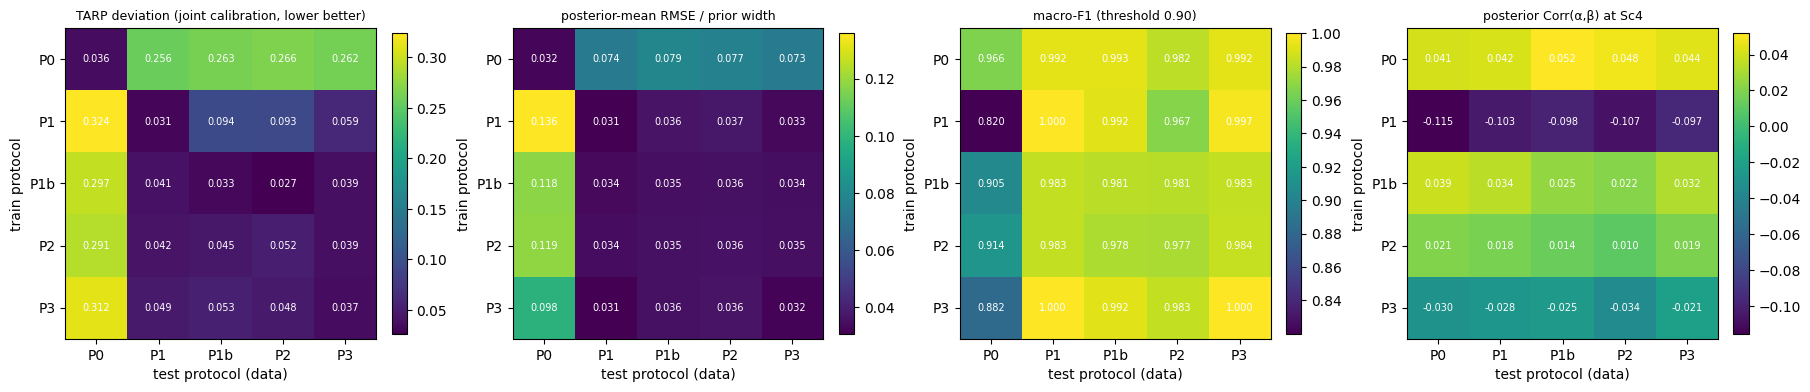

ks_p_a        ks_p_b        tarp_ks_p        tarp_dev        cov90_a  \
        mean    std   mean    std      mean    std     mean    std    mean   
train                                                                        
P0     0.000  0.000  0.000  0.000     0.000  0.000    0.266  0.006   0.266   
P1     0.007  0.012  0.000  0.001     0.001  0.002    0.093  0.019   0.849   
P1b    0.013  0.022  0.345  0.164     0.794  0.148    0.027  0.005   0.917   
P2     0.000  0.000  0.123  0.054     0.155  0.161    0.052  0.013   0.909   
P3     0.031  0.050  0.000  0.000     0.164  0.087    0.048  0.007   0.901   

              ... corr_Sc1        corr_Sc2        corr_Sc3        corr_Sc4  \
         std  ...     mean    std     mean    std     mean    std     mean   
train         ...                                                            
P0     0.018  ...    0.039  0.032    0.667  0.118    0.022  0.016    0.048   
P1     0.034  ...   -0.132  0.031    0.640  0.025   -0.036  0.056   -0.107   
P1b    0.008  ...    0.025  0.045    0.419  0.020    0.027  0.022    0.022   
P2     0.025  ...    0.006  0.040    0.369  0.020    0.028  0.026    0.010   
P3     0.017  ...   -0.053  0.070    0.561  0.025   -0.033  0.042   -0.034   

             corr_Sc7         
         std     mean    std  
train                         
P0     0.039    0.184  0.047  
P1     0.028    0.209  0.123  
P1b    0.056    0.288  0.099  
P2     0.022    0.317  0.074  
P3     0.022    0.244  0.077  

[5 rows x 28 columns]

In [7]:
m = load("29fx_e3_matrix.csv")
metrics = [("tarp_dev", "TARP deviation (joint calibration, lower better)"),
           ("rmse_norm", "posterior-mean RMSE / prior width"),
           ("macro_f1", "macro-F1 (threshold 0.90)"),
           ("corr_Sc4", "posterior Corr(α,β) at Sc4")]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)
for ax, (k, title) in zip(axes, metrics):
    tab = m.groupby(["train", "test"])[k].mean().unstack().reindex(index=P, columns=P)
    im = ax.imshow(tab.values, cmap="viridis")
    ax.set_xticks(range(5), P); ax.set_yticks(range(5), P)
    ax.set_xlabel("test protocol (data)"); ax.set_ylabel("train protocol"); ax.set_title(title, fontsize=9)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{tab.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=7)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGS / "29fx_e3_matrix.png", dpi=150); plt.show()
cols = ["ks_p_a", "ks_p_b", "tarp_ks_p", "tarp_dev", "cov90_a", "cov90_b", "rmse_norm", "macro_f1",
        "leak_sbc_mean", "corr_Sc1", "corr_Sc2", "corr_Sc3", "corr_Sc4", "corr_Sc7"]
display(m[m.test == "P2"].groupby("train")[cols].agg(["mean", "std"]).round(3))

### Per-scenario detail on the decision column (P2)

In [8]:
sc = load("29fx_e3_scenarios.csv")
display(sc[sc.test == "P2"].groupby(["train", "scenario"])[
    ["alpha_hat", "beta_hat", "bias_a", "bias_b", "cov90_truth_a", "cov90_truth_b",
     "corr_ab_mean", "class_acc"]].mean().round(3))

alpha_hat  beta_hat  bias_a  bias_b  \
train scenario                                                    
P0    Sc1_closed_healthy        0.998     0.982  -0.002  -0.018   
      Sc2_closed_fouling        0.928     0.555  -0.072  -0.145   
      Sc3_closed_decay          0.696     0.992  -0.004  -0.008   
      Sc4_closed_combined       0.839     0.797  -0.011  -0.053   
      Sc5_closed_saturated      1.033     0.460   0.033   0.060   
      Sc7_closed_drift          0.971     0.679  -0.029  -0.171   
P1    Sc1_closed_healthy        1.002     0.988   0.002  -0.012   
      Sc2_closed_fouling        0.991     0.698  -0.009  -0.002   
      Sc3_closed_decay          0.699     0.999  -0.001  -0.001   
      Sc4_closed_combined       0.850     0.844  -0.000  -0.006   
      Sc5_closed_saturated      1.008     0.442   0.008   0.042   
      Sc7_closed_drift          0.965     0.588  -0.035  -0.262   
P1b   Sc1_closed_healthy        1.001     0.999   0.001  -0.001   
      Sc2_closed_fouling        0.996     0.696  -0.004  -0.004   
      Sc3_closed_decay          0.700     1.014   0.000   0.014   
      Sc4_closed_combined       0.850     0.855   0.000   0.005   
      Sc5_closed_saturated      1.012     0.443   0.012   0.043   
      Sc7_closed_drift          0.945     0.557  -0.055  -0.293   
P2    Sc1_closed_healthy        1.001     0.999   0.001  -0.001   
      Sc2_closed_fouling        0.995     0.696  -0.005  -0.004   
      Sc3_closed_decay          0.698     1.014  -0.002   0.014   
      Sc4_closed_combined       0.849     0.854  -0.001   0.004   
      Sc5_closed_saturated      1.012     0.442   0.012   0.042   
      Sc7_closed_drift          0.945     0.560  -0.055  -0.290   
P3    Sc1_closed_healthy        1.000     0.986   0.000  -0.014   
      Sc2_closed_fouling        0.993     0.693  -0.007  -0.007   
      Sc3_closed_decay          0.699     0.997  -0.001  -0.003   
      Sc4_closed_combined       0.850     0.844  -0.000  -0.006   
      Sc5_closed_saturated      1.012     0.441   0.012   0.041   
      Sc7_closed_drift          0.965     0.569  -0.035  -0.281   

                            cov90_truth_a  cov90_truth_b  corr_ab_mean  \
train scenario                                                           
P0    Sc1_closed_healthy            0.878          0.811         0.039   
      Sc2_closed_fouling            0.000          0.000         0.667   
      Sc3_closed_decay              0.556          0.856         0.022   
      Sc4_closed_combined           0.244          0.611         0.048   
      Sc5_closed_saturated          0.011          0.000         0.541   
      Sc7_closed_drift              0.056          0.011         0.184   
P1    Sc1_closed_healthy            0.867          0.767        -0.132   
      Sc2_closed_fouling            0.667          0.867         0.640   
      Sc3_closed_decay              0.856          0.900        -0.036   
      Sc4_closed_combined           0.822          0.400        -0.107   
      Sc5_closed_saturated          0.744          0.000         0.487   
      Sc7_closed_drift              0.311          0.000         0.209   
P1b   Sc1_closed_healthy            0.956          0.911         0.025   
      Sc2_closed_fouling            0.933          0.922         0.419   
      Sc3_closed_decay              0.978          0.989         0.027   
      Sc4_closed_combined           0.933          0.922         0.022   
      Sc5_closed_saturated          0.722          0.000         0.386   
      Sc7_closed_drift              0.133          0.000         0.288   
P2    Sc1_closed_healthy            0.889          0.889         0.006   
      Sc2_closed_fouling            0.889          0.933         0.369   
      Sc3_closed_decay              0.878          0.956         0.028   
      Sc4_closed_combined           0.867          0.922         0.010   
      Sc5_closed_saturated          0.678          0.000         0.407   
      Sc7_closed_drift           

## Selection (applies the pre-set rule)

In [9]:
S.stage_select()
sel = json.loads((R / "29fx_selection.json").read_text())
print("CHOICE:", sel["choice"])
if sel["flag"]:
    print("FLAG:", sel["flag"])

       min_ks_med  tarp_ks_med  tarp_dev    rmse  rmse_se      f1  n_seeds  worst_offcol_tarp_dev  P0col_tarp_dev  P0col_rmse  eligible
train                                                                                                                                  
P0         0.0000       0.0000    0.2660  0.0771   0.0031  0.9823        3                 0.2627          0.0360      0.0322     False
P1         0.0000       0.0011    0.0927  0.0375   0.0002  0.9672        3                 0.0940          0.3240      0.1359     False
P1b        0.0001       0.8173    0.0267  0.0357   0.0002  0.9805        3                 0.0407          0.2967      0.1175     False
P2         0.0000       0.1163    0.0520  0.0358   0.0002  0.9769        3                 0.0453          0.2913      0.1186     False
P3         0.0000       0.1932    0.0480  0.0362   0.0001  0.9832        3                 0.0533          0.3120      0.0983     False
NO PROTOCOL PASSES CALIBRATION ON THE P2 COLUMN 

## Conclusions (2026-11-08 run)

**1. The selection rule was flagged, and the cause is not the protocol.** No protocol is
eligible because every one fails the *full-set α* SBC KS test, including the matched
diagonal (P1→P1 p≈10⁻¹⁴, P2→P2 p≈10⁻¹⁰). β KS and joint TARP pass for the realistic
protocols, and for P1b the α 90% coverage is 0.91–0.93. The α failure is a small shift of
the α posterior whose sign changes between seeds and protocols (mean rank 0.43–0.59, ~0.1
posterior sd) for a parameter
the data pin down very tightly (posterior sd ≈ 1.5% of the prior width): an estimator
accuracy limit at 5k simulations, shared by all protocols. It is nb31's job (budget), not
a reason to prefer one protocol. The rule's fallback (lowest P2 TARP deviation) picks
**P1b**, which is also best on every other P2-column calibration measure (TARP KS p 0.82,
β KS 0.40, 90% coverage 0.91/0.89, RMSE tied with P2).

**2. The noise-free deterministic start (P1) is not innocuous.** Trained on P1 and tested on
realistic data, β is overconfident (90% coverage 0.76–0.78; 0.40 at Sc4) and the Fisher
information shows a spurious *negative* α–β correlation (−0.41 at Sc1, −0.69 at Sc4) that
disappears with a stationary start (P1b: −0.04, +0.04). An exactly-steady initial state
leaks θ through the deterministic steady-state map.

**3. The old β bias is reproduced exactly by the protocol mismatch.** Train P0 (abrupt
fault) → test P2 (incipient): Sc2 β̂ = 0.555 (bias −0.145, coverage 0), against the old
manuscript value 0.551 (bias −0.149). The bias was a training/evaluation initial-state
mismatch, not physics.

**4. The α–β correlation is now physically interpretable.** With the fixed controller and a
stationary start, α and β are nearly uncorrelated while the loop is in control (SBI: Sc1
+0.03, Sc3 +0.03, Sc4 +0.02; FIM: −0.04, −0.06, +0.04) and positively correlated when the
coolant valve saturates (Sc2 +0.42, Sc5 +0.39; FIM Sc2 +0.48). Saturation opens the loop,
and the open-loop heat-balance compensation (less heat generated ≈ less heat removed)
appears with the expected positive sign. The near-unity negative correlation of the earlier
work came from the controller bug plus the noise-free start.

**5. The hand-crafted summaries are close to sufficient here.** Under P1b the raw-trajectory
Cramér–Rao bounds are within ~20% of the 29-D summary bounds (β: 0.033 vs 0.036 at Sc1), and
the implied correlations agree in sign and roughly in size. The diagonal-covariance FIM is
wrong (Sc2 I_αα/I_ββ 4.4 vs 36 with full covariance).

**6. Scenario-design issues found** (user decisions, see the re-run plan): Sc5's true β = 0.40
sits *on* the prior's lower edge, so its 0% β coverage is a boundary artefact; Sc2 (β = 0.70)
saturates under the fixed law, so there is no unsaturated fouling scenario; Sc7's β bias
(−0.29) is the known temperature-drift confound (nb09).

## Review — user sign-off required before nb31

The selection is flagged, so nb31 will not start until the user approves a protocol here.
Set `USER_APPROVES_CHOICE = True` (and edit `REASON` if needed) and run this cell.

In [15]:
USER_APPROVES_CHOICE = True
CHOICE = "P1b"
REASON = ("Flag caused by full-set alpha SBC failing for every protocol incl. matched pairs "
          "(5k-budget estimator limit, handled by nb31); P1b best on all other P2-column calibration measures.")
if USER_APPROVES_CHOICE:
    (R / "29fx_selection_review.json").write_text(json.dumps(
        {"choice": CHOICE, "approved": True, "reason": REASON, "time": time.ctime()}, indent=2))
    print("approved:", CHOICE)
else:
    print("not approved yet -- nb31 will refuse to start")

approved: P1b


## E4 (optional) — window length
If the protocols converge as the window grows, the initial state matters only for short
windows: a practical rule for readers. Off by default (`RUN_E4`).

In [16]:
if RUN_E4:
    S.stage_e4(THREADS)
e4 = load("29fx_e4_windows.csv")
if e4 is not None:
    display(e4.pivot_table(index=["train", "test"], columns="window_min", values=["rmse_norm", "tarp_dev"]).round(4))

## Reading guide for the manuscript
- The off-diagonal cell **train P0 → test P1** reproduces, under the fixed controller, the
  mechanism behind the old β bias (training/evaluation initial-state mismatch).
- Main text: the E3 heatmap. SI: E1, E2, E4.
- The chosen protocol is used by nb31 (budget) and every downstream notebook.

In [17]:
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")

notebook wall time 59.9 min
